# Project 9 — Manager selection: three global equity funds vs. the index
Candidates: Capital Group New Perspective (ANWPX, Class A), Dodge & Cox Global Stock (DODWX, Class I),
T. Rowe Price Global Stock (PRGSX, Investor Class) and the passive alternative iShares MSCI ACWI ETF (ACWI).
Monthly total returns October 2016 – September 2026; factor regressions end August 2026 (latest French data).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd
import statsmodels.api as sm

from common import data as D
from common.plotting import PALETTE, setup, source
from src import acwi as A

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
FUNDS = ["ANWPX", "DODWX", "PRGSX"]
NAMES = {"ANWPX": "Capital Group New Perspective (A)", "DODWX": "Dodge & Cox Global Stock (I)",
         "PRGSX": "T. Rowe Price Global Stock (Inv.)", "ACWI": "iShares MSCI ACWI ETF"}
SRC = "Source: yfinance (total returns), Kenneth French Data Library; author's calculations."

## Pillar 1 — Performance (10 years)

In [2]:
px = D.prices(FUNDS + ["ACWI"], "2016-09-01", "2026-10-01", DATA / "fund_prices_daily.csv")
R = D.monthly_returns(px).loc["2016-10":"2026-09"]
f5 = D.french("Developed_5_Factors", DATA / "ff_developed_5f.csv")
mom = D.french("Developed_Mom_Factor", DATA / "ff_developed_mom.csv")
F6 = f5.join(mom).rename(columns={"WML": "Mom"})
F6.columns = [c.strip() for c in F6.columns]
FAC = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
ann = lambda r: (1 + r).prod() ** (12 / len(r)) - 1


def mdd(r):
    w = (1 + r).cumprod()
    return float((w / w.cummax() - 1).min())


perf, regs = {}, {}
for f in FUNDS + ["ACWI"]:
    a = R[f] - R["ACWI"]
    te = a.std() * np.sqrt(12)
    roll = ((1 + R[f]).rolling(36).apply(np.prod, raw=True) - (1 + R["ACWI"]).rolling(36).apply(np.prod, raw=True)).dropna()
    up, dn = R["ACWI"] > 0, R["ACWI"] < 0
    d = pd.concat([R[f] - F6["RF"], F6[FAC]], axis=1).dropna()
    m = sm.OLS(d.iloc[:, 0], sm.add_constant(d[FAC])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    regs[f] = m
    perf[f] = {"Ann. return": ann(R[f]), "Excess vs ACWI (ann.)": ann(R[f]) - ann(R["ACWI"]),
               "Tracking error": te, "Information ratio": (a.mean() * 12 / te) if te > 0 else np.nan,
               "Alpha 6F (ann.)": m.params["const"] * 12, "t(alpha)": m.tvalues["const"],
               "Up-capture": ann(R.loc[up, f]) / ann(R.loc[up, "ACWI"]), "Down-capture": ann(R.loc[dn, f]) / ann(R.loc[dn, "ACWI"]),
               "% rolling 3y beating ACWI": float((roll > 0).mean()) if f != "ACWI" else np.nan,
               "Max drawdown": mdd(R[f]), "Volatility": R[f].std() * np.sqrt(12)}
PERF = pd.DataFrame(perf).T
LOAD = pd.DataFrame({f: {**{c: regs[f].params[c] for c in FAC}, **{f"t({c})": regs[f].tvalues[c] for c in FAC},
                         "R2": regs[f].rsquared} for f in regs}).T
REG_END = d.index[-1]
print(f"Returns {R.index[0]:%b %Y} – {R.index[-1]:%b %Y} ({len(R)} months); regressions to {d.index[-1]:%b %Y}")
PERF

Returns Oct 2016 – Sep 2026 (120 months); regressions to Aug 2026


,Ann. return,Excess vs ACWI (ann.),Tracking error,Information ratio,Alpha 6F (ann.),t(alpha),Up-capture,Down-capture,% rolling 3y beating ACWI,Max drawdown,Volatility
ANWPX,0.129806,0.005299,0.036758,0.182608,0.003079,0.381234,1.061746,1.045750,0.588235,-0.319830,0.159086
DODWX,0.111604,-0.012903,0.078242,-0.091315,-0.008173,-0.677865,0.984247,1.042372,0.400000,-0.309992,0.173474
PRGSX,0.159490,0.034983,0.066818,0.533652,0.030269,1.942485,1.165504,1.025234,0.647059,-0.354929,0.176342
ACWI,0.124507,0.000000,0.000000,NaN,-0.002390,-0.748773,1.000000,1.000000,NaN,-0.257384,0.145849


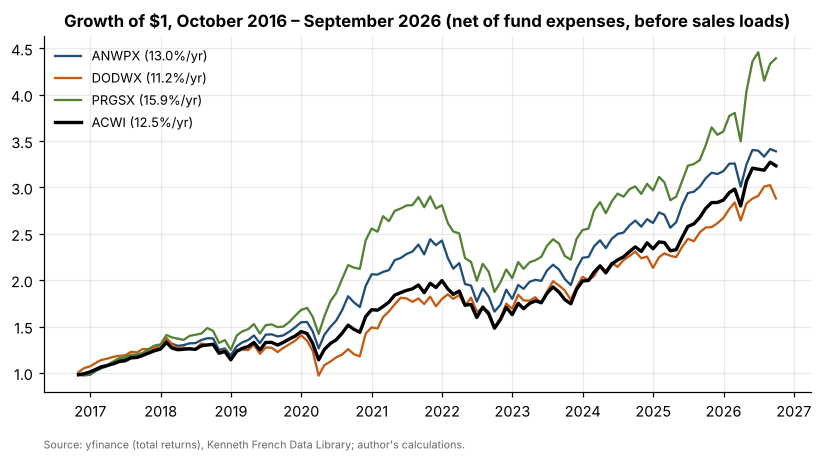

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, f in enumerate(FUNDS + ["ACWI"]):
    w = (1 + R[f]).cumprod()
    ax.plot(w.index, w, lw=2.2 if f == "ACWI" else 1.5, color="black" if f == "ACWI" else PALETTE[i], label=f"{f} ({ann(R[f]):.1%}/yr)")
ax.set_title("Growth of $1, October 2016 – September 2026 (net of fund expenses, before sales loads)")
ax.legend(fontsize=8.5); source(ax, SRC)
fig.savefig(FIG / "fig_growth.png"); plt.show()

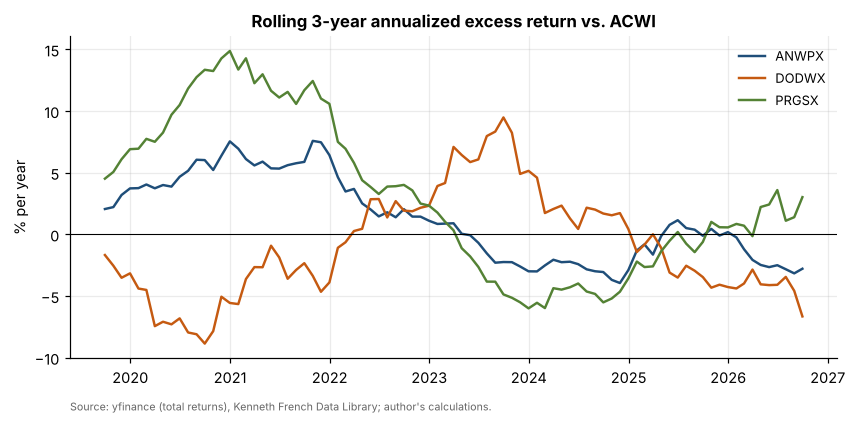

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, f in enumerate(FUNDS):
    rel = ((1 + R[f]).rolling(36).apply(np.prod, raw=True) ** (1 / 3) - (1 + R["ACWI"]).rolling(36).apply(np.prod, raw=True) ** (1 / 3))
    ax.plot(rel.index, rel * 100, lw=1.6, color=PALETTE[i], label=f)
ax.axhline(0, color="black", lw=0.7); ax.set_ylabel("% per year")
ax.set_title("Rolling 3-year annualized excess return vs. ACWI"); ax.legend(fontsize=8.5); source(ax, SRC)
fig.savefig(FIG / "fig_rolling_excess.png"); plt.show()

## Pillar 2 — People (prospectus portfolio-manager disclosures, ~2021 vs. latest)

In [5]:
PEOPLE = {
    "ANWPX": {"source_now": "497K filed 2025-11-28", "source_then": "497K filed 2020-11-30",
              "managers_now": {"Aline Avzaradel": 2025, "Barbara Burtin": 2018, "Noriko Honda Chen": 2012, "Patrice Collette": 2018,
                               "Brady L. Enright": 2005, "Kohei Higashi": 2021, "Robert W. Lovelace": 2001, "Anne-Marie Peterson": 2021,
                               "Andraz Razen": 2015, "Steven T. Watson": 2006},
              "managers_then": ["Joanna F. Jonsson", "Robert W. Lovelace", "Noriko Honda Chen", "Brady L. Enright", "Jonathan Knowles",
                                "Andraz Razen", "Steven T. Watson"], "as_of_year": 2025},
    "DODWX": {"source_now": "497K filed 2026-05-01", "source_then": "497K filed 2021-04-30",
              "years_on_fund_now": {"Steven C. Voorhis": 18, "Lily S. Beischer": 18, "Roger G. Kuo": 16, "David C. Hoeft": 10, "Raymond J. Mertens": 5},
              "managers_then": ["Diana S. Strandberg", "David C. Hoeft", "Roger G. Kuo", "Steven C. Voorhis", "Karol Marcin", "Lily S. Beischer",
                                "Raymond J. Mertens"], "as_of_year": 2026},
    "PRGSX": {"source_now": "497K filed 2025-12-23", "source_then": "497K filed 2021-02-26",
              "managers_now": {"David Eiswert": 2012}, "managers_then": ["David J. Eiswert"], "as_of_year": 2025},
}
ppl = {}
for f, p in PEOPLE.items():
    if "years_on_fund_now" in p:
        tenures = list(p["years_on_fund_now"].values()); now = list(p["years_on_fund_now"])
    else:
        tenures = [p["as_of_year"] - y for y in p["managers_now"].values()]; now = list(p["managers_now"])
    surname = lambda n: n.replace(" J.", "").split()[-1]
    departed = [n for n in p["managers_then"] if surname(n) not in {surname(x) for x in now}]
    ppl[f] = {"Team size (named managers)": len(now), "Average tenure on fund (yrs)": float(np.mean(tenures)),
              "Longest tenure (yrs)": max(tenures), "Departures in ~5 years": len(departed),
              "Departed": ", ".join(departed) if departed else "none", "Single-manager key-person risk": len(now) == 1}
PEOPLE_T = pd.DataFrame(ppl).T
PEOPLE_T

,Team size (named managers),Average tenure on fund (yrs),Longest tenure (yrs),Departures in ~5 years,Departed,Single-manager key-person risk
ANWPX,10,10.8,24,2,"Joanna F. Jonsson, Jonathan Knowles",False
DODWX,5,13.4,18,2,"Diana S. Strandberg, Karol Marcin",False
PRGSX,1,13.0,13,0,none,True


## Pillar 4 — Price (prospectus fee tables)

In [6]:
PRICE = pd.DataFrame({
    "ANWPX": {"Expense ratio": 0.0071, "Max front-end sales load": 0.0575, "Source": "497K 2025-11-28, Class A"},
    "DODWX": {"Expense ratio": 0.0062, "Max front-end sales load": 0.0, "Source": "497K 2026-05-01, Class I"},
    "PRGSX": {"Expense ratio": 0.0081, "Max front-end sales load": 0.0, "Source": "497K 2025-12-23, Investor Class"},
    "ACWI": {"Expense ratio": 0.0032, "Max front-end sales load": 0.0, "Source": "497K 2025-11-28"}}).T
PRICE["Expense ratio"] = PRICE["Expense ratio"].astype(float)
PRICE["Max front-end sales load"] = PRICE["Max front-end sales load"].astype(float)
PRICE["All-in annual cost (load over 10y)"] = PRICE["Expense ratio"] + PRICE["Max front-end sales load"] / 10
PRICE["Cost gap vs ACWI"] = PRICE["All-in annual cost (load over 10y)"] - PRICE.loc["ACWI", "All-in annual cost (load over 10y)"]
# Load-adjusted 10-year return for ANWPX (pays the 5.75% load once at purchase)
PERF["Ann. return after max load"] = [((1 + R[f]).prod() * (1 - PRICE.loc[f, "Max front-end sales load"])) ** (12 / len(R)) - 1 for f in PERF.index]
PRICE

,Expense ratio,Max front-end sales load,Source,All-in annual cost (load over 10y),Cost gap vs ACWI
ANWPX,0.0071,0.0575,"497K 2025-11-28, Class A",0.01285,0.00965
DODWX,0.0062,0.0000,"497K 2026-05-01, Class I",0.00620,0.00300
PRGSX,0.0081,0.0000,"497K 2025-12-23, Investor Class",0.00810,0.00490
ACWI,0.0032,0.0000,497K 2025-11-28,0.00320,0.00000


## Pillar 5 — Portfolio: active share, concentration, sector and region tilts (Form N-PORT and iShares)

In [7]:
def nport_eq(label, d):
    x = pd.read_csv(DATA / "nport" / f"{label}_{d}.csv")
    x = x[x["asset_cat"].isin(["EC", "EP"])].copy()
    x["key"] = x["isin"].fillna(x["name"].str.upper())
    return x.groupby("key")["pct_val"].sum() / 100


def active_share(wf, wb):
    idx = wf.index.union(wb.index)
    wf, wb = wf.reindex(idx).fillna(0), wb.reindex(idx).fillna(0)
    return 0.5 * float((wf / wf.sum() - wb / wb.sum()).abs().sum())


HD = {"ANWPX": "2026-06-30", "DODWX": "2026-06-30", "PRGSX": "2026-07-31"}
ACW = {d: nport_eq("ACWI", d) for d in ["2026-04-30", "2026-07-31"]}
port = {}
for f, d in HD.items():
    wf = nport_eq(f, d)
    asj = active_share(wf, ACW["2026-07-31"])
    asa = active_share(wf, ACW["2026-04-30"])
    port[f] = {"Holdings date": d, "Holdings (equity lines)": len(wf),
               "Active share vs ACWI 31 Jul 2026": asj, "Active share vs ACWI 30 Apr 2026": asa,
               "Top-10 weight": float(wf.sort_values(ascending=False).head(10).sum() / wf.sum())}
    hc = pd.read_csv(DATA / f"{f}_holdings_classified.csv")
    port[f]["Level 3 (unlisted) weight"] = float(hc.loc[hc["fair_value_level"] == 3, "pct_val"].sum() / hc["pct_val"].sum())
wb = ACW["2026-07-31"]
port["ACWI"] = {"Holdings date": "2026-07-31", "Holdings (equity lines)": len(wb), "Active share vs ACWI 31 Jul 2026": 0.0,
                "Active share vs ACWI 30 Apr 2026": active_share(wb, ACW["2026-04-30"]),
                "Top-10 weight": float(wb.sort_values(ascending=False).head(10).sum() / wb.sum()), "Level 3 (unlisted) weight": 0.0}
PORT = pd.DataFrame(port).T
PORT

,Holdings date,Holdings (equity lines),Active share vs ACWI 31 Jul 2026,Active share vs ACWI 30 Apr 2026,Top-10 weight,Level 3 (unlisted) weight
ANWPX,2026-06-30,289,0.595557,0.598259,0.272596,0.0
DODWX,2026-06-30,95,0.851372,0.850854,0.277434,0.0
PRGSX,2026-07-31,135,0.680456,0.690094,0.290704,0.048707
ACWI,2026-07-31,2192,0.0,0.068595,0.243376,0.0


In [8]:
REGION = {"US": "United States", "CA": "Other developed", "GB": "Europe", "CH": "Europe", "DE": "Europe", "FR": "Europe",
          "NL": "Europe", "DK": "Europe", "SE": "Europe", "IT": "Europe", "ES": "Europe", "BE": "Europe", "FI": "Europe",
          "NO": "Europe", "IE": "Europe", "AT": "Europe", "PT": "Europe", "LU": "Europe", "JE": "Europe", "JP": "Japan",
          "AU": "Other developed", "HK": "Other developed", "SG": "Other developed", "IL": "Other developed", "NZ": "Other developed"}
region = lambda cc: REGION.get(cc, "Emerging markets")
ish = {"2026-06-30": A.read_ishares(DATA / "acwi_holdings_20260630.raw"), "2026-07-31": A.read_ishares(DATA / "acwi_holdings_20260731.raw")}
sect, reg = {}, {}
for f, d in HD.items():
    h = pd.read_csv(DATA / f"{f}_holdings_classified.csv")
    w = h["pct_val"] / h["pct_val"].sum()
    sect[f] = w.groupby(h["sector"]).sum()
    loc = h["location"].map(lambda x: A.ISO.get(x, x))
    reg[f] = w.groupby(loc.map(region)).sum()
for d in ["2026-07-31"]:
    e = ish[d][ish[d]["Asset Class"] == "Equity"]
    w = e["Weight (%)"] / e["Weight (%)"].sum()
    sect["ACWI"] = w.groupby(e["Sector"]).sum()
    reg["ACWI"] = w.groupby(e["Location"].map(lambda x: A.ISO.get(x, x)).map(region)).sum()
SECT = pd.DataFrame(sect).fillna(0)
# iShares labels the sector "Communication"; the GICS name used in the fund classification is "Communication Services"
SECT = SECT.rename(index={"Communication Services": "Communication"}).groupby(level=0).sum()
SECT = SECT.rename(index={"Communication": "Communication Services", "Unclassified": "Unclassified (mostly unlisted)"})
REG = pd.DataFrame(reg).fillna(0)
SECT_TILT = SECT[FUNDS].sub(SECT["ACWI"], axis=0)
REG_TILT = REG[FUNDS].sub(REG["ACWI"], axis=0)
SECT.round(3), REG.round(3)

(                                ANWPX  DODWX  PRGSX   ACWI
 Communication Services          0.093  0.085  0.042  0.079
 Consumer Discretionary          0.118  0.077  0.079  0.090
 Consumer Staples                0.049  0.020  0.022  0.048
 Energy                          0.017  0.036  0.033  0.040
 Financials                      0.098  0.233  0.090  0.171
 Health Care                     0.106  0.205  0.081  0.084
 Industrials                     0.144  0.113  0.109  0.109
 Information Technology          0.319  0.159  0.441  0.303
 Materials                       0.031  0.055  0.023  0.035
 Real Estate                     0.009  0.010  0.000  0.016
 Unclassified (mostly unlisted)  0.004  0.000  0.061  0.000
 Utilities                       0.010  0.006  0.019  0.025,
                   ANWPX  DODWX  PRGSX   ACWI
 Emerging markets  0.101  0.174  0.115  0.111
 Europe            0.249  0.246  0.206  0.142
 Japan             0.050  0.008  0.057  0.051
 Other developed   0.048  0.031  0.

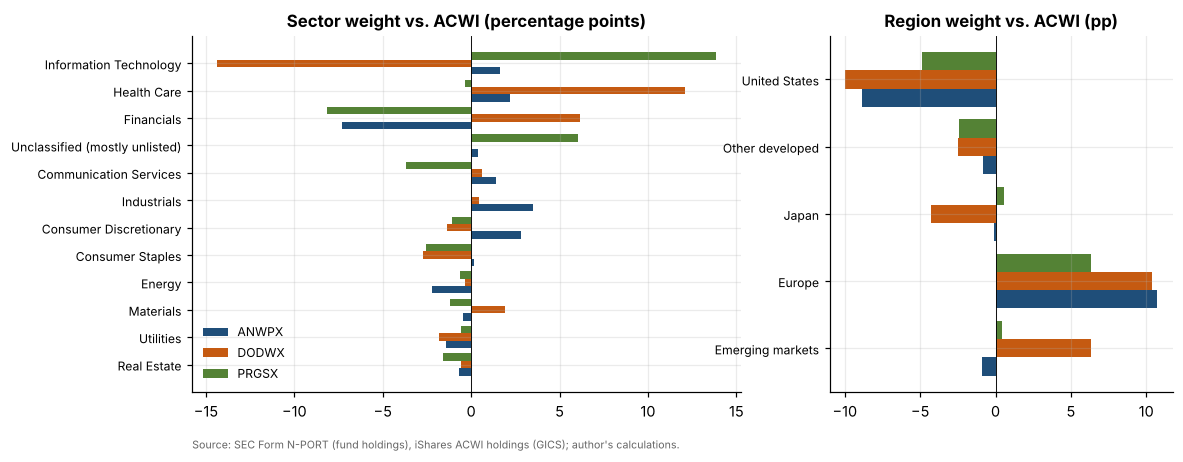

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
order = SECT_TILT.abs().max(axis=1).sort_values().index
y = np.arange(len(order))
for i, f in enumerate(FUNDS):
    axes[0].barh(y + (i - 1) * 0.27, SECT_TILT.loc[order, f] * 100, 0.27, color=PALETTE[i], label=f)
axes[0].set_yticks(y, order, fontsize=8); axes[0].axvline(0, color="black", lw=0.6)
axes[0].set_title("Sector weight vs. ACWI (percentage points)"); axes[0].legend(fontsize=8)
ro = REG_TILT.index
y2 = np.arange(len(ro))
for i, f in enumerate(FUNDS):
    axes[1].barh(y2 + (i - 1) * 0.27, REG_TILT.loc[ro, f] * 100, 0.27, color=PALETTE[i])
axes[1].set_yticks(y2, ro, fontsize=8); axes[1].axvline(0, color="black", lw=0.6)
axes[1].set_title("Region weight vs. ACWI (pp)")
source(axes[0], "Source: SEC Form N-PORT (fund holdings), iShares ACWI holdings (GICS); author's calculations.")
fig.savefig(FIG / "fig_tilts.png"); plt.show()

## Pillar 3 — Process: does the evidence match the stated philosophy?
Stated approach (prospectus): New Perspective — multinational companies, attractively valued, long-term,
multi-manager system; Dodge & Cox — value, long-term, committee-based; T. Rowe Global Stock — growth,
single portfolio manager, "high-quality companies capable of achieving and sustaining above-average, long-term earnings
growth", large- and mid-cap focus, "broadly diversified". (The brief labels PRGSX "concentrated"; its prospectus does not,
so the checks test the prospectus wording.) Checks combine the factor loadings and holdings evidence.

In [10]:
L = LOAD
checks = {
    "ANWPX": [("Growth-leaning: HML loading <= 0", L.loc["ANWPX", "HML"] <= 0),
              ("Quality/large multinationals: RMW >= 0", L.loc["ANWPX", "RMW"] >= 0),
              ("Mostly developed markets (EM weight <= ACWI)", REG.loc["Emerging markets", "ANWPX"] <= REG.loc["Emerging markets", "ACWI"]),
              ("Diversified multi-manager book: top-10 < 40%", PORT.loc["ANWPX", "Top-10 weight"] < 0.40)],
    "DODWX": [("Value: HML loading > 0", L.loc["DODWX", "HML"] > 0),
              ("Value is statistically significant: t(HML) > 2", L.loc["DODWX", "t(HML)"] > 2),
              ("Contrarian, not momentum: Mom loading <= 0", L.loc["DODWX", "Mom"] <= 0),
              ("Underweight expensive growth sector IT", SECT_TILT.loc["Information Technology", "DODWX"] < 0)],
    "PRGSX": [("Growth: HML loading < 0", L.loc["PRGSX", "HML"] < 0),
              ("Growth is statistically significant: t(HML) < -2", L.loc["PRGSX", "t(HML)"] < -2),
              ("High-quality companies: RMW loading >= 0", L.loc["PRGSX", "RMW"] >= 0),
              ("Large- and mid-cap focus: SMB loading <= 0", L.loc["PRGSX", "SMB"] <= 0)]}
PROC = {f: {"Checks passed": sum(bool(v) for _, v in c), "Checks": "; ".join(f"{k}: {'yes' if v else 'no'}" for k, v in c)} for f, c in checks.items()}
PROC = pd.DataFrame(PROC).T
LOAD.round(2), PROC

(       Mkt-RF   SMB   HML   RMW   CMA   Mom  t(Mkt-RF)  t(SMB)  t(HML)  \
 ANWPX    1.02 -0.06 -0.17 -0.02 -0.07  0.02      46.53   -1.34   -3.50   
 DODWX    1.07  0.04  0.41 -0.07  0.08 -0.18      34.22    0.46    5.77   
 PRGSX    1.06 -0.03 -0.20 -0.43 -0.27  0.14      31.28   -0.24   -1.91   
 ACWI     0.98 -0.10 -0.01 -0.01  0.03  0.01      88.97   -3.58   -0.52   
 
        t(RMW)  t(CMA)  t(Mom)    R2  
 ANWPX   -0.34   -1.02    0.63  0.97  
 DODWX   -0.72    0.82   -3.95  0.94  
 PRGSX   -3.08   -1.79    2.13  0.92  
 ACWI    -0.37    0.90    0.29  0.99  ,
       Checks passed                                             Checks
 ANWPX             3  Growth-leaning: HML loading <= 0: yes; Quality...
 DODWX             4  Value: HML loading > 0: yes; Value is statisti...
 PRGSX             2  Growth: HML loading < 0: yes; Growth is statis...)

## Scorecard (rules fixed in advance; scores 1–5)
- **Performance (25%)**: mean of four sub-scores: (a) 10y excess return vs ACWI >2% 5, 1–2% 4, 0–1% 3, −1–0% 2, <−1% 1;
  (b) information ratio >0.5 5, 0.3–0.5 4, 0.1–0.3 3, −0.1–0.1 2, <−0.1 1; (c) share of rolling 3y periods beating ACWI
  >75% 5, 60–75% 4, 45–60% 3, 30–45% 2, <30% 1; (d) max drawdown vs ACWI's: better by >5pp 5, better 0–5pp 4, worse 0–3pp 3,
  worse 3–6pp 2, worse >6pp 1. ACWI = 3 (it is the benchmark).
- **People (20%)**: average tenure ≥10y 5, 7–10 4, 4–7 3, <4 2; −1 if departures ≥ 2; −1 if a single manager (key-person risk).
  ACWI = 5 (no key-person risk).
- **Process (20%)**: 4 of 4 checks 5, 3 of 4 4, 2 of 4 3, 1 of 4 2, 0 of 4 1. ACWI = 5 (replicates its index).
- **Price (20%)**: all-in cost gap vs ACWI (load spread over 10 years) ≤0.10pp 5, 0.10–0.30 4, 0.30–0.50 3, 0.50–0.80 2, >0.80 1.
- **Portfolio (15%)**: active share ≥80% 5, 70–80% 4, 60–70% 3, 50–60% 2, <50% 1; −1 if top-10 > 50%. ACWI = 3.

In [11]:
def band(x, cuts, scores):
    for c, s in zip(cuts, scores):
        if x > c:
            return s
    return scores[-1]


def perf_score(f):
    if f == "ACWI":
        return 3.0
    p = PERF.loc[f]
    a = band(p["Excess vs ACWI (ann.)"], [0.02, 0.01, 0.0, -0.01], [5, 4, 3, 2, 1])
    b = band(p["Information ratio"], [0.5, 0.3, 0.1, -0.1], [5, 4, 3, 2, 1])
    c = band(p["% rolling 3y beating ACWI"], [0.75, 0.60, 0.45, 0.30], [5, 4, 3, 2, 1])
    dd = p["Max drawdown"] - PERF.loc["ACWI", "Max drawdown"]          # positive = shallower drawdown
    dsc = band(dd, [0.05, 0.0, -0.03, -0.06], [5, 4, 3, 2, 1])
    return float(np.mean([a, b, c, dsc]))


def people_score(f):
    if f == "ACWI":
        return 5
    p = PEOPLE_T.loc[f]
    s = band(p["Average tenure on fund (yrs)"], [9.999, 7, 4], [5, 4, 3, 2])
    s -= 1 if p["Departures in ~5 years"] >= 2 else 0
    s -= 1 if p["Single-manager key-person risk"] else 0
    return max(s, 1)


def process_score(f):
    return 5 if f == "ACWI" else {4: 5, 3: 4, 2: 3, 1: 2, 0: 1}[int(PROC.loc[f, "Checks passed"])]


def price_score(f):
    return band(-PRICE.loc[f, "Cost gap vs ACWI"], [-0.001, -0.003, -0.005, -0.008], [5, 4, 3, 2, 1])


def portfolio_score(f):
    if f == "ACWI":
        return 3
    s = band(PORT.loc[f, "Active share vs ACWI 31 Jul 2026"], [0.8, 0.7, 0.6, 0.5], [5, 4, 3, 2, 1])
    s -= 1 if PORT.loc[f, "Top-10 weight"] > 0.5 else 0
    return max(s, 1)


W = {"Performance": 0.25, "People": 0.20, "Process": 0.20, "Price": 0.20, "Portfolio": 0.15}
SC = pd.DataFrame({f: {"Performance": perf_score(f), "People": people_score(f), "Process": process_score(f),
                       "Price": price_score(f), "Portfolio": portfolio_score(f)} for f in FUNDS + ["ACWI"]}).T
SC["Weighted score"] = sum(SC[k] * w for k, w in W.items())
best = SC.drop("ACWI")["Weighted score"].idxmax()
ir_best = PERF.loc[best, "Information ratio"]
recommend = best if ir_best >= 0.2 else "ACWI"
print(f"Highest-scoring active fund: {best} ({SC.loc[best, 'Weighted score']:.2f}); 10y IR {ir_best:.2f} -> recommend {recommend}")
SC.round(2)

Highest-scoring active fund: DODWX (3.79); 10y IR -0.09 -> recommend ACWI


,Performance,People,Process,Price,Portfolio,Weighted score
ANWPX,2.50,4.0,4.0,1.0,2.0,2.72
DODWX,1.75,4.0,5.0,4.0,5.0,3.79
PRGSX,3.75,4.0,3.0,3.0,3.0,3.39
ACWI,3.00,5.0,5.0,5.0,3.0,4.20


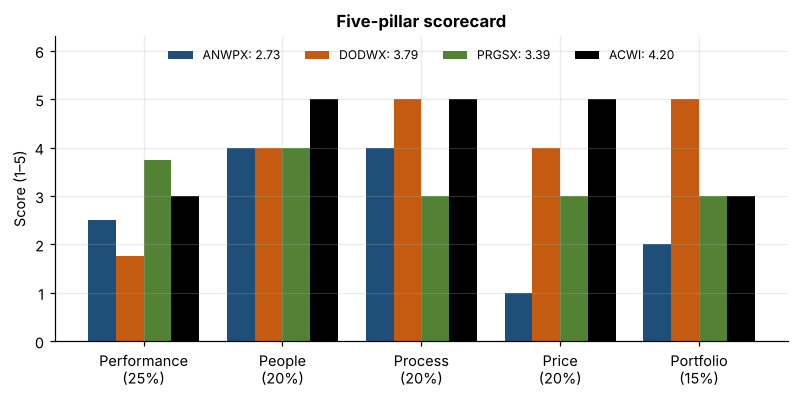

In [12]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
x = np.arange(len(W))
for i, f in enumerate(FUNDS + ["ACWI"]):
    ax.bar(x + (i - 1.5) * 0.2, SC.loc[f, list(W)], 0.2, color="black" if f == "ACWI" else PALETTE[i], label=f"{f}: {SC.loc[f, 'Weighted score']:.2f}")
ax.set_xticks(x, [f"{k}\n({int(v * 100)}%)" for k, v in W.items()]); ax.set_ylim(0, 6.3); ax.set_ylabel("Score (1–5)")
ax.set_title("Five-pillar scorecard"); ax.legend(fontsize=8, ncol=4, loc="upper center")
fig.savefig(FIG / "fig_scorecard.png"); plt.show()

## Save

In [13]:
PERF.to_csv(DATA / "performance.csv"); LOAD.to_csv(DATA / "factor_loadings.csv"); PEOPLE_T.to_csv(DATA / "people.csv")
PRICE.to_csv(DATA / "price.csv"); PORT.to_csv(DATA / "portfolio.csv"); SECT.to_csv(DATA / "sector_weights.csv"); REG.to_csv(DATA / "region_weights.csv")
PROC.to_csv(DATA / "process_checks.csv"); SC.to_csv(DATA / "scorecard.csv")
json.dump({"best_active": best, "ir_best": float(ir_best), "recommend": recommend, "weights": W,
           "returns_start": str(R.index[0].date()), "returns_end": str(R.index[-1].date()),
           "reg_end": str(REG_END.date())}, open(DATA / "meta.json", "w"), indent=2)